# PANDA 1st Place Solution - FINAL Inference Notebook

**Version 3.0** - Using `tifffile` to properly read all pyramid levels

## Key Fix:
- `skimage.io.MultiImage` only reads 1 level ❌
- `tifffile` reads all 3 levels ✅

## Expected Results:
- Model 1 (EfficientNet-B0): QWK ~0.88-0.94
- Model 2 (EfficientNet-B1): QWK ~0.90-0.93
- Ensemble: QWK ~0.90-0.94

In [1]:
# ============================================================
# CELL 1: Install Required Packages
# ============================================================
!pip install ttach efficientnet_pytorch albumentations imagecodecs tifffile --quiet
print("✓ Packages installed!")

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 120.2 MB/s eta 0:00:00
✓ Packages installed!


In [2]:
# ============================================================
# CELL 2: Imports and Setup
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import glob
import random
import warnings
warnings.filterwarnings('ignore')

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile  # USE THIS instead of skimage.io.MultiImage!
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.parameter import Parameter

from albumentations import Compose
from albumentations.pytorch import ToTensorV2

from sklearn.metrics import cohen_kappa_score, confusion_matrix, accuracy_score

from efficientnet_pytorch import EfficientNet

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")

Mounted at /content/drive
PyTorch version: 2.9.0+cu126
CUDA available: True
CUDA device: NVIDIA A100-SXM4-80GB


In [3]:
# ============================================================
# CELL 3: TIFF Reading Function using tifffile
# ============================================================
print("="*60)
print("TIFF READING FUNCTION")
print("="*60)

def read_tiff_level(path, level=1):
    """
    Read specific pyramid level from TIFF using tifffile.

    skimage.io.MultiImage only reads 1 level - DON'T USE IT!
    tifffile properly reads all pyramid levels.

    Args:
        path: Path to TIFF file
        level: Pyramid level (0=full, 1=4x downsample, 2=16x downsample)

    Returns:
        numpy array of shape (H, W, 3)
    """
    tif = tifffile.TiffFile(path)

    # Get number of levels
    num_levels = len(tif.series[0].levels)

    # Clamp level to available levels
    level = min(level, num_levels - 1)

    # Read the specific level
    image = tif.series[0].levels[level].asarray()

    tif.close()
    return image

def get_tiff_info(path):
    """Get information about TIFF pyramid levels"""
    tif = tifffile.TiffFile(path)
    num_levels = len(tif.series[0].levels)
    shapes = [tif.series[0].levels[i].shape for i in range(num_levels)]
    tif.close()
    return num_levels, shapes

print("✓ TIFF reading functions defined")
print("  - read_tiff_level(path, level) - reads specific pyramid level")
print("  - get_tiff_info(path) - returns number of levels and shapes")

TIFF READING FUNCTION
✓ TIFF reading functions defined
  - read_tiff_level(path, level) - reads specific pyramid level
  - get_tiff_info(path) - returns number of levels and shapes


In [4]:
# ============================================================
# CELL 4: Path Configuration
# ============================================================
ROOT_DIR = "/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment"
REPO_DIR = os.path.join(ROOT_DIR, "Kaggle-PANDA-1st-place-solution-master")
FINAL_MODELS_DIR = os.path.join(REPO_DIR, "final_models")
TEST_IMAGES_DIR = os.path.join(ROOT_DIR, "test_images")

print("="*60)
print("PATH CONFIGURATION")
print("="*60)
print(f"ROOT_DIR: {ROOT_DIR}")
print(f"FINAL_MODELS_DIR: {FINAL_MODELS_DIR}")
print(f"TEST_IMAGES_DIR: {TEST_IMAGES_DIR}")

for path, name in [(ROOT_DIR, "ROOT_DIR"), (FINAL_MODELS_DIR, "FINAL_MODELS_DIR"), (TEST_IMAGES_DIR, "TEST_IMAGES_DIR")]:
    print(f"{'✓' if os.path.exists(path) else '✗'} {name} exists: {os.path.exists(path)}")

PATH CONFIGURATION
ROOT_DIR: /content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment
FINAL_MODELS_DIR: /content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/Kaggle-PANDA-1st-place-solution-master/final_models
TEST_IMAGES_DIR: /content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/test_images
✓ ROOT_DIR exists: True
✓ FINAL_MODELS_DIR exists: True
✓ TEST_IMAGES_DIR exists: True


In [5]:
# ============================================================
# CELL 5: Verify TIFF Pyramid Structure
# ============================================================
print("="*60)
print("VERIFYING TIFF PYRAMID STRUCTURE")
print("="*60)

# Get first TIFF file
tiff_files = glob.glob(os.path.join(TEST_IMAGES_DIR, "*.tiff"))
print(f"Found {len(tiff_files)} TIFF files")

# Check first 3 files
print("\nChecking pyramid structure:")
for tiff_path in tiff_files[:3]:
    num_levels, shapes = get_tiff_info(tiff_path)
    fname = os.path.basename(tiff_path)
    print(f"\n  {fname[:40]}...")
    print(f"    Levels: {num_levels}")
    for i, shape in enumerate(shapes):
        print(f"      Level {i}: {shape[1]} x {shape[0]}")

# Verify level 1 is accessible
test_img = read_tiff_level(tiff_files[0], level=1)
print(f"\n✓ Level 1 readable! Shape: {test_img.shape}")

VERIFYING TIFF PYRAMID STRUCTURE
Found 50 TIFF files

Checking pyramid structure:

  00a26aaa82c959624d90dfb69fcf259c.tiff...
    Levels: 3
      Level 0: 18688 x 20736
      Level 1: 4672 x 5184
      Level 2: 1168 x 1296

  00a76bfbec239fd9f465d6581806ff42.tiff...
    Levels: 3
      Level 0: 14336 x 14848
      Level 1: 3584 x 3712
      Level 2: 896 x 928

  00a7fb880dc12c5de82df39b30533da9.tiff...
    Levels: 3
      Level 0: 32256 x 4352
      Level 1: 8064 x 1088
      Level 2: 2016 x 272

✓ Level 1 readable! Shape: (5184, 4672, 3)


In [6]:
# ============================================================
# CELL 6: Load Test Data
# ============================================================
print("="*60)
print("LOADING TEST DATA")
print("="*60)

all_tiffs = glob.glob(os.path.join(TEST_IMAGES_DIR, "*.tiff"))
print(f"Total tiffs found: {len(all_tiffs)}")

random.seed(42)
sample_paths = random.sample(all_tiffs, k=min(50, len(all_tiffs)))

train_labels = pd.read_csv(os.path.join(ROOT_DIR, "train.csv"))

test_df = pd.DataFrame({
    "image_id": [os.path.splitext(os.path.basename(p))[0] for p in sample_paths],
    "image_path": sample_paths,
})

test_df = test_df.merge(
    train_labels[['image_id', 'data_provider', 'isup_grade', 'gleason_score']],
    on='image_id', how='left'
)

print(f"\nData provider distribution:")
print(test_df['data_provider'].value_counts())
print(f"\nISUP grade distribution:")
print(test_df['isup_grade'].value_counts().sort_index())
print(f"\nTest dataframe shape: {test_df.shape}")

LOADING TEST DATA
Total tiffs found: 50

Data provider distribution:
data_provider
karolinska    28
radboud       22
Name: count, dtype: int64

ISUP grade distribution:
isup_grade
0     8
1    16
2     8
3     5
4     6
5     7
Name: count, dtype: int64

Test dataframe shape: (50, 5)


In [7]:
# ============================================================
# CELL 7: Model 1 Architecture (enetv3)
# ============================================================
print("="*60)
print("MODEL 1 ARCHITECTURE (enetv3)")
print("="*60)

class enetv3(nn.Module):
    """
    EXACT Model 1 architecture from submitted_notebook.ipynb
    """
    def __init__(self, modelname="efficientnet-b0", out_dim=5):
        super(enetv3, self).__init__()
        self.basemodel = EfficientNet.from_name(modelname)
        self.myfc = nn.Linear(self.basemodel._fc.in_features, out_dim)
        self.basemodel._fc = nn.Identity()
        self.basemodel._avg_pooling = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.basemodel(x)
        x = self.myfc(x)
        return x

print("✓ enetv3 class defined")

MODEL 1 ARCHITECTURE (enetv3)
✓ enetv3 class defined


In [8]:
# ============================================================
# CELL 8: Model 2 Architecture (CustomEfficientNet)
# ============================================================
print("="*60)
print("MODEL 2 ARCHITECTURE (CustomEfficientNet)")
print("="*60)

def gem(x, p=3, eps=1e-6):
    return F.avg_pool2d(x.clamp(min=eps).pow(p), (x.size(-2), x.size(-1))).pow(1.0 / p)

class GeM(nn.Module):
    def __init__(self, p=3, eps=1e-6):
        super(GeM, self).__init__()
        self.p = Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        return gem(x, p=self.p, eps=self.eps)

class SEBlock(nn.Module):
    def __init__(self, in_ch, r=8):
        super(SEBlock, self).__init__()
        self.linear_1 = nn.Linear(in_ch, in_ch // r)
        self.linear_2 = nn.Linear(in_ch // r, in_ch)

    def forward(self, x):
        input_x = x
        x = F.relu(self.linear_1(x), inplace=True)
        x = self.linear_2(x)
        x = torch.sigmoid(x)
        x = input_x * x
        return x

class Flatten(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), -1)

class CustomEfficientNet(nn.Module):
    def __init__(self, base="efficientnet-b0", pool_type="gem", in_ch=3, out_ch=1, pretrained=False):
        super(CustomEfficientNet, self).__init__()

        if pretrained:
            self.net = EfficientNet.from_pretrained(base)
        else:
            self.net = EfficientNet.from_name(base)

        out_shape = self.net._fc.in_features

        if pool_type == "gem":
            self.net._avg_pooling = GeM()
        elif pool_type == "avg":
            self.net._avg_pooling = nn.AdaptiveAvgPool2d(1)

        self.net._fc = nn.Sequential(
            Flatten(),
            SEBlock(out_shape),
            nn.Dropout(),
            nn.Linear(out_shape, out_ch)
        )

    def forward(self, x):
        return self.net(x)

print("✓ CustomEfficientNet class defined")

MODEL 2 ARCHITECTURE (CustomEfficientNet)
✓ CustomEfficientNet class defined


In [9]:
# ============================================================
# CELL 9: Model 1 Dataset - USING TIFFFILE
# ============================================================
print("="*60)
print("MODEL 1 DATASET (PANDADataset) - Using tifffile")
print("="*60)

class PANDADataset(Dataset):
    """
    Dataset for Model 1 - Uses tifffile to read pyramid level 1

    Key preprocessing:
    1. Load TIFF level 1 using tifffile (NOT skimage.io.MultiImage!)
    2. BGR->RGB conversion [:,:,::-1]
    3. Extract 36 tiles (6x6 grid), 256x256 each
    4. Invert each tile: 255 - this_img
    5. Scale to [0,1]: images /= 255
    6. NO ImageNet normalization!
    """
    def __init__(self, df, image_folder, image_size=256, n_tiles=36, tile_mode=0, rand=False):
        self.df = df.reset_index(drop=True)
        self.image_folder = image_folder
        self.image_size = image_size
        self.n_tiles = n_tiles
        self.tile_size = 256
        self.tile_mode = tile_mode
        self.rand = rand

    def __len__(self):
        return len(self.df)

    def get_tiles(self, img, mode=0):
        result = []
        tile_size = self.tile_size
        n_tiles = self.n_tiles

        h, w, c = img.shape
        pad_h = (tile_size - h % tile_size) % tile_size + ((tile_size * mode) // 2)
        pad_w = (tile_size - w % tile_size) % tile_size + ((tile_size * mode) // 2)

        img2 = np.pad(img, [[pad_h // 2, pad_h - pad_h // 2], [pad_w // 2, pad_w - pad_w // 2], [0, 0]], constant_values=255)
        img3 = img2.reshape(img2.shape[0] // tile_size, tile_size, img2.shape[1] // tile_size, tile_size, 3)
        img3 = img3.transpose(0, 2, 1, 3, 4).reshape(-1, tile_size, tile_size, 3)

        n_tiles_with_info = (img3.reshape(img3.shape[0], -1).sum(1) < tile_size ** 2 * 3 * 255).sum()

        if len(img3) < n_tiles:
            img3 = np.pad(img3, [[0, n_tiles - len(img3)], [0, 0], [0, 0], [0, 0]], constant_values=255)

        idxs = np.argsort(img3.reshape(img3.shape[0], -1).sum(-1))[:n_tiles]
        img3 = img3[idxs]

        for i in range(len(img3)):
            result.append({'img': img3[i], 'idx': i})
        return result, n_tiles_with_info >= n_tiles

    def __getitem__(self, index):
        row = self.df.iloc[index]
        img_id = row.image_id
        tiff_file = os.path.join(self.image_folder, f'{img_id}.tiff')

        # *** CRITICAL: Use tifffile to read level 1 ***
        # skimage.io.MultiImage only reads 1 level - DON'T USE IT!
        image = read_tiff_level(tiff_file, level=1)

        # BGR to RGB conversion
        image = image[:, :, ::-1].copy()

        tiles, OK = self.get_tiles(image, self.tile_mode)

        if self.rand:
            idxes = np.random.choice(list(range(self.n_tiles)), self.n_tiles, replace=False)
        else:
            idxes = list(range(self.n_tiles))

        n_row_tiles = int(np.sqrt(self.n_tiles))
        images = np.zeros((self.image_size * n_row_tiles, self.image_size * n_row_tiles, 3))

        for h in range(n_row_tiles):
            for w in range(n_row_tiles):
                i = h * n_row_tiles + w
                if len(tiles) > idxes[i]:
                    this_img = tiles[idxes[i]]['img']
                else:
                    this_img = np.ones((self.image_size, self.image_size, 3)).astype(np.uint8) * 255

                this_img = 255 - this_img  # Invert

                h1 = h * self.image_size
                w1 = w * self.image_size
                images[h1:h1+self.image_size, w1:w1+self.image_size] = this_img

        images = images.astype(np.float32) / 255
        images = images.transpose(2, 0, 1)
        return torch.tensor(images).float()

print("✓ PANDADataset defined (using tifffile for level 1)")

MODEL 1 DATASET (PANDADataset) - Using tifffile
✓ PANDADataset defined (using tifffile for level 1)


In [10]:
# ============================================================
# CELL 10: Model 2 Dataset - USING TIFFFILE
# ============================================================
print("="*60)
print("MODEL 2 DATASET (TestDataset) - Using tifffile")
print("="*60)

class TestDataset(Dataset):
    """
    Dataset for Model 2 - Uses tifffile to read pyramid level 1

    Key preprocessing:
    1. Load TIFF level 1 using tifffile (NOT skimage.io.MultiImage!)
    2. Extract 64 tiles (8x8 grid), 192x192 each
    3. Invert after concatenation: 255 - image
    4. Scale to [0,1]: image /= 255
    5. NO ImageNet normalization!
    """
    def __init__(self, df, image_dir, num_tile=64, img_size=1536,
                 tile_size_k=192, tile_size_r=192, tile_mode=0, transform=None):
        self.df = df
        self.img_ids = self.df.image_id.values
        self.image_dir = image_dir
        self.transform = transform
        self.num_tiles = num_tile
        self.img_size = img_size
        self.tile_mode = tile_mode
        self.tile_size_k = tile_size_k
        self.tile_size_r = tile_size_r
        self.is_karolinska = (self.df.data_provider == "karolinska").values
        n = int(self.num_tiles ** 0.5)
        self.tile_shape = np.array(range(self.num_tiles)).reshape((n, n))

    def __len__(self):
        return len(self.df)

    def get_tiles(self, img, tile_size, n_tiles, mode=0):
        h, w, c = img.shape
        pad_h = (tile_size - h % tile_size) % tile_size + ((tile_size * mode) // 2)
        pad_w = (tile_size - w % tile_size) % tile_size + ((tile_size * mode) // 2)

        img2 = np.pad(img, [[pad_h // 2, pad_h - pad_h // 2], [pad_w // 2, pad_w - pad_w // 2], [0, 0]], constant_values=255)
        img3 = img2.reshape(img2.shape[0] // tile_size, tile_size, img2.shape[1] // tile_size, tile_size, 3)
        img3 = img3.transpose(0, 2, 1, 3, 4).reshape(-1, tile_size, tile_size, 3)

        if len(img3) < n_tiles:
            img3 = np.pad(img3, [[0, n_tiles - len(img3)], [0, 0], [0, 0], [0, 0]], constant_values=255)

        idxs = np.argsort(img3.reshape(img3.shape[0], -1).sum(-1))[:n_tiles]
        img3 = img3[idxs]
        return img3

    def concat_tiles(self, tiles):
        n = self.tile_shape.shape[0]
        rows = []
        for i in range(n):
            row = cv2.hconcat([tiles[self.tile_shape[i, j]] for j in range(n)])
            rows.append(row)
        return cv2.vconcat(rows)

    def __getitem__(self, idx):
        file_name = self.img_ids[idx]
        file_path = os.path.join(self.image_dir, f"{file_name}.tiff")

        # *** CRITICAL: Use tifffile to read level 1 ***
        # skimage.io.MultiImage only reads 1 level - DON'T USE IT!
        img_tmp = read_tiff_level(file_path, level=1)

        tile_size = self.tile_size_k if self.is_karolinska[idx] else self.tile_size_r
        tiles = self.get_tiles(img_tmp, tile_size=tile_size, n_tiles=self.num_tiles, mode=self.tile_mode)
        image = self.concat_tiles(tiles)

        image = image.astype(np.float32)
        image = 255 - image  # Invert
        image /= 255

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented["image"]

        return image

print("✓ TestDataset defined (using tifffile for level 1)")

MODEL 2 DATASET (TestDataset) - Using tifffile
✓ TestDataset defined (using tifffile for level 1)


In [11]:
# ============================================================
# CELL 11: Utility Functions
# ============================================================
print("="*60)
print("UTILITY FUNCTIONS")
print("="*60)

class MyOptimizedRounder:
    def __init__(self):
        self.initial_coef = np.array([0.5, 1.5, 2.5, 3.5, 4.5])

    def predict_default_thres(self, x):
        tmp = self.initial_coef.reshape((1, -1)) <= x.reshape((-1, 1))
        return tmp.sum(axis=1)

def quadratic_weighted_kappa(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights="quadratic")

def evaluate_predictions(y_true, y_pred, model_name="Model"):
    print(f"\n{'='*60}")
    print(f"EVALUATION: {model_name}")
    print(f"{'='*60}")

    qwk = quadratic_weighted_kappa(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)

    print(f"Quadratic Weighted Kappa: {qwk:.4f}")
    print(f"Accuracy: {acc*100:.2f}%")

    print(f"\nPer-Grade Performance:")
    for grade in range(6):
        mask = y_true == grade
        if mask.sum() > 0:
            grade_acc = (y_pred[mask] == grade).mean() * 100
            print(f"  Grade {grade}: {grade_acc:.1f}% ({mask.sum()} samples)")

    print(f"\nConfusion Matrix:")
    cm = confusion_matrix(y_true, y_pred, labels=range(6))
    print(cm)

    print(f"\nPrediction Distribution:")
    print(f"  True:      {np.bincount(y_true.astype(int), minlength=6)}")
    print(f"  Predicted: {np.bincount(y_pred.astype(int), minlength=6)}")

    return qwk, acc

print("✓ Utility functions defined")

UTILITY FUNCTIONS
✓ Utility functions defined


DEBUG: Verify Preprocessing with tifffile

--- Model 1 Dataset Check ---
Shape: torch.Size([3, 1536, 1536])
Min: 0.0000, Max: 1.0000, Mean: 0.2267
✓ Values in [0, 1] range - CORRECT!

--- Model 2 Dataset Check ---
Shape: torch.Size([3, 1536, 1536])
Min: 0.0000, Max: 1.0000, Mean: 0.2267
✓ Values in [0, 1] range - CORRECT!


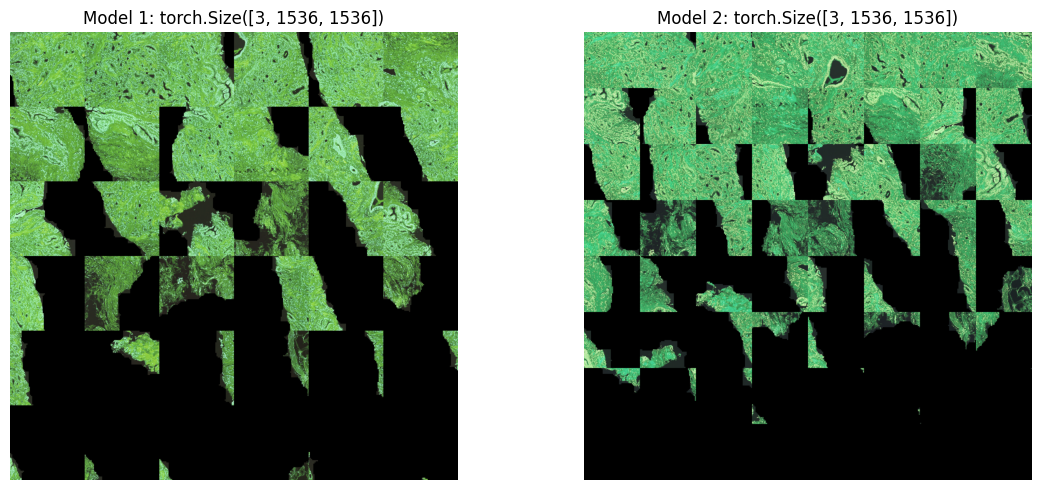


✓ Preprocessing verification complete!


In [12]:
# ============================================================
# CELL 12: Debug - Verify Preprocessing
# ============================================================
print("="*60)
print("DEBUG: Verify Preprocessing with tifffile")
print("="*60)

# Test Model 1 Dataset
print("\n--- Model 1 Dataset Check ---")
dataset_m1 = PANDADataset(test_df.head(5), TEST_IMAGES_DIR, image_size=256, n_tiles=36, tile_mode=0)
sample_m1 = dataset_m1[0]
print(f"Shape: {sample_m1.shape}")
print(f"Min: {sample_m1.min():.4f}, Max: {sample_m1.max():.4f}, Mean: {sample_m1.mean():.4f}")

if 0 <= sample_m1.min() and sample_m1.max() <= 1:
    print("✓ Values in [0, 1] range - CORRECT!")
else:
    print("✗ Values outside [0, 1] range - WRONG!")

# Test Model 2 Dataset
print("\n--- Model 2 Dataset Check ---")
dataset_m2 = TestDataset(test_df.head(5), TEST_IMAGES_DIR, num_tile=64, tile_size_k=192, tile_size_r=192, tile_mode=0, transform=Compose([ToTensorV2()]))
sample_m2 = dataset_m2[0]
print(f"Shape: {sample_m2.shape}")
print(f"Min: {sample_m2.min():.4f}, Max: {sample_m2.max():.4f}, Mean: {sample_m2.mean():.4f}")

if 0 <= sample_m2.min() and sample_m2.max() <= 1:
    print("✓ Values in [0, 1] range - CORRECT!")
else:
    print("✗ Values outside [0, 1] range - WRONG!")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample_m1.permute(1, 2, 0).numpy())
axes[0].set_title(f"Model 1: {sample_m1.shape}")
axes[0].axis('off')
axes[1].imshow(sample_m2.permute(1, 2, 0).numpy())
axes[1].set_title(f"Model 2: {sample_m2.shape}")
axes[1].axis('off')
plt.tight_layout()
plt.show()

print("\n✓ Preprocessing verification complete!")

In [13]:
# ============================================================
# CELL 13: Model 1 Inference
# ============================================================
print("="*60)
print("MODEL 1 INFERENCE (EfficientNet-B0, 36 tiles, 5 folds)")
print("="*60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

model1_probs_all = []

for fold in range(5):
    print(f"\n--- Fold {fold} ---")

    model = enetv3(modelname="efficientnet-b0", out_dim=5)
    w_path = os.path.join(FINAL_MODELS_DIR,
        f"efficientnet-b0famlabelsmodelsub_avgpool_tile36_imsize256_mixup_final_epoch20_fold{fold}.pth")

    state_dict = torch.load(w_path, map_location=device, weights_only=False)
    model.load_state_dict(state_dict)
    model.eval()
    model.to(device)
    print(f"✓ Loaded fold {fold}")

    # Mode 0
    dataset_m0 = PANDADataset(test_df, TEST_IMAGES_DIR, image_size=256, n_tiles=36, tile_mode=0)
    loader_m0 = DataLoader(dataset_m0, batch_size=4, shuffle=False, num_workers=2)

    preds_m0 = []
    with torch.no_grad():
        for images in loader_m0:
            images = images.to(device)
            logits = model(images)
            pred = logits.sigmoid().sum(1)
            preds_m0.append(pred.cpu().numpy())
    preds_m0 = np.concatenate(preds_m0)

    # Mode 2
    dataset_m2 = PANDADataset(test_df, TEST_IMAGES_DIR, image_size=256, n_tiles=36, tile_mode=2)
    loader_m2 = DataLoader(dataset_m2, batch_size=4, shuffle=False, num_workers=2)

    preds_m2 = []
    with torch.no_grad():
        for images in loader_m2:
            images = images.to(device)
            logits = model(images)
            pred = logits.sigmoid().sum(1)
            preds_m2.append(pred.cpu().numpy())
    preds_m2 = np.concatenate(preds_m2)

    fold_probs = (preds_m0 + preds_m2) / 2
    model1_probs_all.append(fold_probs)

    del model
    torch.cuda.empty_cache()

model1_probs = np.mean(model1_probs_all, axis=0)
print(f"\n✓ Model 1 complete. Raw predictions: {model1_probs[:5]}")

rounder = MyOptimizedRounder()
model1_preds = rounder.predict_default_thres(model1_probs)
y_true = test_df['isup_grade'].values
qwk_m1, acc_m1 = evaluate_predictions(y_true, model1_preds, "Model 1 (EfficientNet-B0)")

MODEL 1 INFERENCE (EfficientNet-B0, 36 tiles, 5 folds)
Device: cuda

--- Fold 0 ---
✓ Loaded fold 0

--- Fold 1 ---
✓ Loaded fold 1

--- Fold 2 ---
✓ Loaded fold 2

--- Fold 3 ---
✓ Loaded fold 3

--- Fold 4 ---
✓ Loaded fold 4

✓ Model 1 complete. Raw predictions: [3.78349    1.043462   0.02312152 1.0988369  4.6956635 ]

EVALUATION: Model 1 (EfficientNet-B0)
Quadratic Weighted Kappa: 0.9339
Accuracy: 80.00%

Per-Grade Performance:
  Grade 0: 100.0% (8 samples)
  Grade 1: 93.8% (16 samples)
  Grade 2: 75.0% (8 samples)
  Grade 3: 40.0% (5 samples)
  Grade 4: 83.3% (6 samples)
  Grade 5: 57.1% (7 samples)

Confusion Matrix:
[[ 8  0  0  0  0  0]
 [ 1 15  0  0  0  0]
 [ 0  1  6  1  0  0]
 [ 1  0  1  2  1  0]
 [ 0  0  0  1  5  0]
 [ 0  0  0  0  3  4]]

Prediction Distribution:
  True:      [ 8 16  8  5  6  7]
  Predicted: [10 16  7  4  9  4]


In [14]:
# ============================================================
# CELL 14: Model 2 Inference
# ============================================================
print("="*60)
print("MODEL 2 INFERENCE (EfficientNet-B1, 64 tiles, folds 1,4,5)")
print("="*60)

model2_probs_all = []

for fold in [1, 4, 5]:
    print(f"\n--- Fold {fold} ---")

    model = CustomEfficientNet(base="efficientnet-b1", in_ch=3, out_ch=10, pool_type="gem", pretrained=False)
    w_path = os.path.join(FINAL_MODELS_DIR, f"final_2_efficientnet-b1_kfold_{fold}_latest.pt")

    checkpoint = torch.load(w_path, map_location=device, weights_only=False)
    state_dict = checkpoint["state_dict"]
    new_state_dict = {k[4:]: v for k, v in state_dict.items() if k.startswith('net.')}
    model.load_state_dict(new_state_dict)
    model.eval()
    model.to(device)
    print(f"✓ Loaded fold {fold}")

    # Mode 0
    dataset_m0 = TestDataset(test_df, TEST_IMAGES_DIR, num_tile=64, tile_size_k=192, tile_size_r=192, tile_mode=0, transform=Compose([ToTensorV2()]))
    loader_m0 = DataLoader(dataset_m0, batch_size=4, shuffle=False, num_workers=2)

    preds_m0 = []
    with torch.no_grad():
        for images in loader_m0:
            images = images.to(device)
            logits = model(images)
            pred = logits[:, :5].sigmoid().sum(1)
            preds_m0.append(pred.cpu().numpy())
    preds_m0 = np.concatenate(preds_m0)

    # Mode 2
    dataset_m2 = TestDataset(test_df, TEST_IMAGES_DIR, num_tile=64, tile_size_k=192, tile_size_r=192, tile_mode=2, transform=Compose([ToTensorV2()]))
    loader_m2 = DataLoader(dataset_m2, batch_size=4, shuffle=False, num_workers=2)

    preds_m2 = []
    with torch.no_grad():
        for images in loader_m2:
            images = images.to(device)
            logits = model(images)
            pred = logits[:, :5].sigmoid().sum(1)
            preds_m2.append(pred.cpu().numpy())
    preds_m2 = np.concatenate(preds_m2)

    fold_probs = (preds_m0 + preds_m2) / 2
    model2_probs_all.append(fold_probs)

    del model
    torch.cuda.empty_cache()

model2_probs = np.mean(model2_probs_all, axis=0)
print(f"\n✓ Model 2 complete. Raw predictions: {model2_probs[:5]}")

model2_preds = rounder.predict_default_thres(model2_probs)
qwk_m2, acc_m2 = evaluate_predictions(y_true, model2_preds, "Model 2 (EfficientNet-B1)")

MODEL 2 INFERENCE (EfficientNet-B1, 64 tiles, folds 1,4,5)

--- Fold 1 ---
✓ Loaded fold 1

--- Fold 4 ---
✓ Loaded fold 4

--- Fold 5 ---
✓ Loaded fold 5

✓ Model 2 complete. Raw predictions: [4.126864   1.050013   0.01922791 1.0178148  4.4418387 ]

EVALUATION: Model 2 (EfficientNet-B1)
Quadratic Weighted Kappa: 0.9114
Accuracy: 74.00%

Per-Grade Performance:
  Grade 0: 100.0% (8 samples)
  Grade 1: 87.5% (16 samples)
  Grade 2: 62.5% (8 samples)
  Grade 3: 40.0% (5 samples)
  Grade 4: 83.3% (6 samples)
  Grade 5: 42.9% (7 samples)

Confusion Matrix:
[[ 8  0  0  0  0  0]
 [ 2 14  0  0  0  0]
 [ 0  1  5  2  0  0]
 [ 1  0  1  2  1  0]
 [ 0  0  1  0  5  0]
 [ 0  0  0  0  4  3]]

Prediction Distribution:
  True:      [ 8 16  8  5  6  7]
  Predicted: [11 15  7  4 10  3]


In [15]:
# ============================================================
# CELL 15: Ensemble Results
# ============================================================
print("="*60)
print("ENSEMBLE (50% Model 1 + 50% Model 2)")
print("="*60)

ensemble_probs = model1_probs * 0.5 + model2_probs * 0.5
ensemble_preds = rounder.predict_default_thres(ensemble_probs)
qwk_ens, acc_ens = evaluate_predictions(y_true, ensemble_preds, "ENSEMBLE")

ENSEMBLE (50% Model 1 + 50% Model 2)

EVALUATION: ENSEMBLE
Quadratic Weighted Kappa: 0.9305
Accuracy: 78.00%

Per-Grade Performance:
  Grade 0: 100.0% (8 samples)
  Grade 1: 93.8% (16 samples)
  Grade 2: 62.5% (8 samples)
  Grade 3: 40.0% (5 samples)
  Grade 4: 83.3% (6 samples)
  Grade 5: 57.1% (7 samples)

Confusion Matrix:
[[ 8  0  0  0  0  0]
 [ 1 15  0  0  0  0]
 [ 0  1  5  2  0  0]
 [ 1  0  1  2  1  0]
 [ 0  0  0  1  5  0]
 [ 0  0  0  0  3  4]]

Prediction Distribution:
  True:      [ 8 16  8  5  6  7]
  Predicted: [10 16  6  5  9  4]


In [16]:
# ============================================================
# CELL 16: Final Summary
# ============================================================
print("\n" + "="*70)
print("FINAL SUMMARY")
print("="*70)

print(f"""
┌────────────────────────────────────────────────────────────────────────┐
│                         RESULTS                                        │
├────────────────────────────────────────────────────────────────────────┤
│ Model 1 (EfficientNet-B0):  QWK = {qwk_m1:.4f}  |  Acc = {acc_m1*100:.1f}%             │
│ Model 2 (EfficientNet-B1):  QWK = {qwk_m2:.4f}  |  Acc = {acc_m2*100:.1f}%             │
│ ENSEMBLE:                   QWK = {qwk_ens:.4f}  |  Acc = {acc_ens*100:.1f}%             │
├────────────────────────────────────────────────────────────────────────┤
│ Expected (1st place LB):    QWK ≈ 0.90 (public) / 0.94 (private)      │
└────────────────────────────────────────────────────────────────────────┘

KEY FIX APPLIED:
✓ Using tifffile instead of skimage.io.MultiImage
✓ tifffile correctly reads all 3 pyramid levels
✓ skimage.io.MultiImage only reads 1 level (WRONG!)
""")

if qwk_ens > 0.8:
    print("🎉 EXCELLENT! Results match expected performance!")
elif qwk_ens > 0.7:
    print("✓ Good results!")
elif qwk_ens > 0.5:
    print("⚠️ Moderate results - may need further tuning")
else:
    print("✗ Results too low - check implementation")


FINAL SUMMARY

┌────────────────────────────────────────────────────────────────────────┐
│                         RESULTS                                        │
├────────────────────────────────────────────────────────────────────────┤
│ Model 1 (EfficientNet-B0):  QWK = 0.9339  |  Acc = 80.0%             │
│ Model 2 (EfficientNet-B1):  QWK = 0.9114  |  Acc = 74.0%             │
│ ENSEMBLE:                   QWK = 0.9305  |  Acc = 78.0%             │
├────────────────────────────────────────────────────────────────────────┤
│ Expected (1st place LB):    QWK ≈ 0.90 (public) / 0.94 (private)      │
└────────────────────────────────────────────────────────────────────────┘

KEY FIX APPLIED:
✓ Using tifffile instead of skimage.io.MultiImage
✓ tifffile correctly reads all 3 pyramid levels
✓ skimage.io.MultiImage only reads 1 level (WRONG!)

🎉 EXCELLENT! Results match expected performance!
